# Social Media Shares Prediction

**Problem:** publishers want to know which articles will spread on social media before they publish, to decide what to promote and when. This project studies what drives social media shares and builds a model that scores an article's chance of being popular using only information available at publishing time.

**Data:** [Online News Popularity](https://archive.ics.uci.edu/dataset/332/online+news+popularity) from the UCI Machine Learning Repository (Fernandes, Vinagre, Cortez and Sernadela, 2015). 39,644 Mashable articles published between January 2013 and December 2014, with 58 features describing each article and its number of social media shares.

**Target:** an article is **popular** if it reached 1,400 or more shares (the median).

## Why this dataset

The first version of this project used a "social media engagement" dataset with 12,000 posts. Checking it showed:

- `engagement_rate` was exactly (likes + shares + comments) / impressions. Its reported 96% accuracy came from using those counts as inputs.
- Likes, shares, comments and impressions were independent, uniformly distributed random numbers, and 487 posts had more interactions than impressions.
- Using only information available before posting (platform, topic, sentiment, brand, time, hashtags and the full post text), no model did better than chance: R2 of -0.02 and ROC-AUC of 0.50.

A dataset with no real signal cannot support an engagement model, so this version uses real articles with real share counts.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.data import load_raw, clean, feature_columns, time_split, TARGET, POPULAR_THRESHOLD
from src.analysis import (
    WEEK_ORDER, shares_by, weekend_test, rank_correlations,
    plot_shares_distribution, plot_popularity_overview, plot_monthly,
)
from src.model import (
    compare_classifiers, regression_result, validation_check, feature_importance, lift_table,
    plot_roc, plot_lift, plot_feature_importance,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 70)

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load and check the data

In [2]:
raw = load_raw()
print(raw.shape)
raw.head(3)

(39644, 61)


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,num_keywords,data_channel_is_lifestyle,data_channel_is_entertainment,data_channel_is_bus,data_channel_is_socmed,data_channel_is_tech,data_channel_is_world,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg,self_reference_min_shares,self_reference_max_shares,self_reference_avg_sharess,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday,is_weekend,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,4.680365,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,496.0,496.0,496.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.500331,0.378279,0.040005,0.041263,0.040123,0.521617,0.092562,0.045662,0.013699,0.769231,0.230769,0.378636,0.100000,0.7,-0.350000,-0.600,-0.200000,0.5,-0.1875,0.0,0.1875,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,4.913725,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.799756,0.050047,0.050096,0.050101,0.050001,0.341246,0.148948,0.043137,0.015686,0.733333,0.266667,0.286915,0.033333,0.7,-0.118750,-0.125,-0.100000,0.0,0.0000,0.5,0.0000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,4.393365,6.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,918.0,918.0,918.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.217792,0.033334,0.033351,0.033334,0.682188,0.702222,0.323333,0.056872,0.009479,0.857143,0.142857,0.495833,0.100000,1.0,-0.466667,-0.800,-0.133333,0.0,0.0000,0.5,0.0000,1500


In [3]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()), "| duplicate URLs:", int(raw["url"].duplicated().sum()))
print("Unique-word ratio above 1:", int((raw["n_unique_tokens"] > 1).sum()))
print("Articles with no body text:", int((raw["n_tokens_content"] == 0).sum()))
kw = [c for c in raw.columns if c.startswith("kw_")]
print("Negative values in keyword share columns:", int((raw[kw] < 0).sum().sum()), "(mostly kw_min_min = -1)")

Missing values: 0
Duplicate rows: 0 | duplicate URLs: 0
Unique-word ratio above 1: 1
Articles with no body text: 1181
Negative values in keyword share columns: 23819 (mostly kw_min_min = -1)


In [4]:
df, cleaning_log = clean(raw)
cleaning_log

,step,rows or values
0,Article with a unique-word ratio above 1 (impo...,1
1,Negative keyword share values (used as 'no dat...,23818
2,Articles with no body text (mostly video posts...,1181


- One article has a unique-word ratio of 701, which is impossible (it must be between 0 and 1), so it is removed.
- The keyword columns use -1 and other negative numbers for "no data", which would mislead a model, so they are set to missing.
- 1,181 articles have no body text. Most contain a video (median of one video), so they are real posts, kept and flagged.
- `url` and `timedelta` (days between publishing and data collection) are not inputs. Neither describes the article at publishing time.

## 3. Shares

In [5]:
df[TARGET].describe().round(0)

count     39643.0
mean       3395.0
std       11627.0
min           1.0
25%         946.0
50%        1400.0
75%        2800.0
max      843300.0
Name: shares, dtype: float64

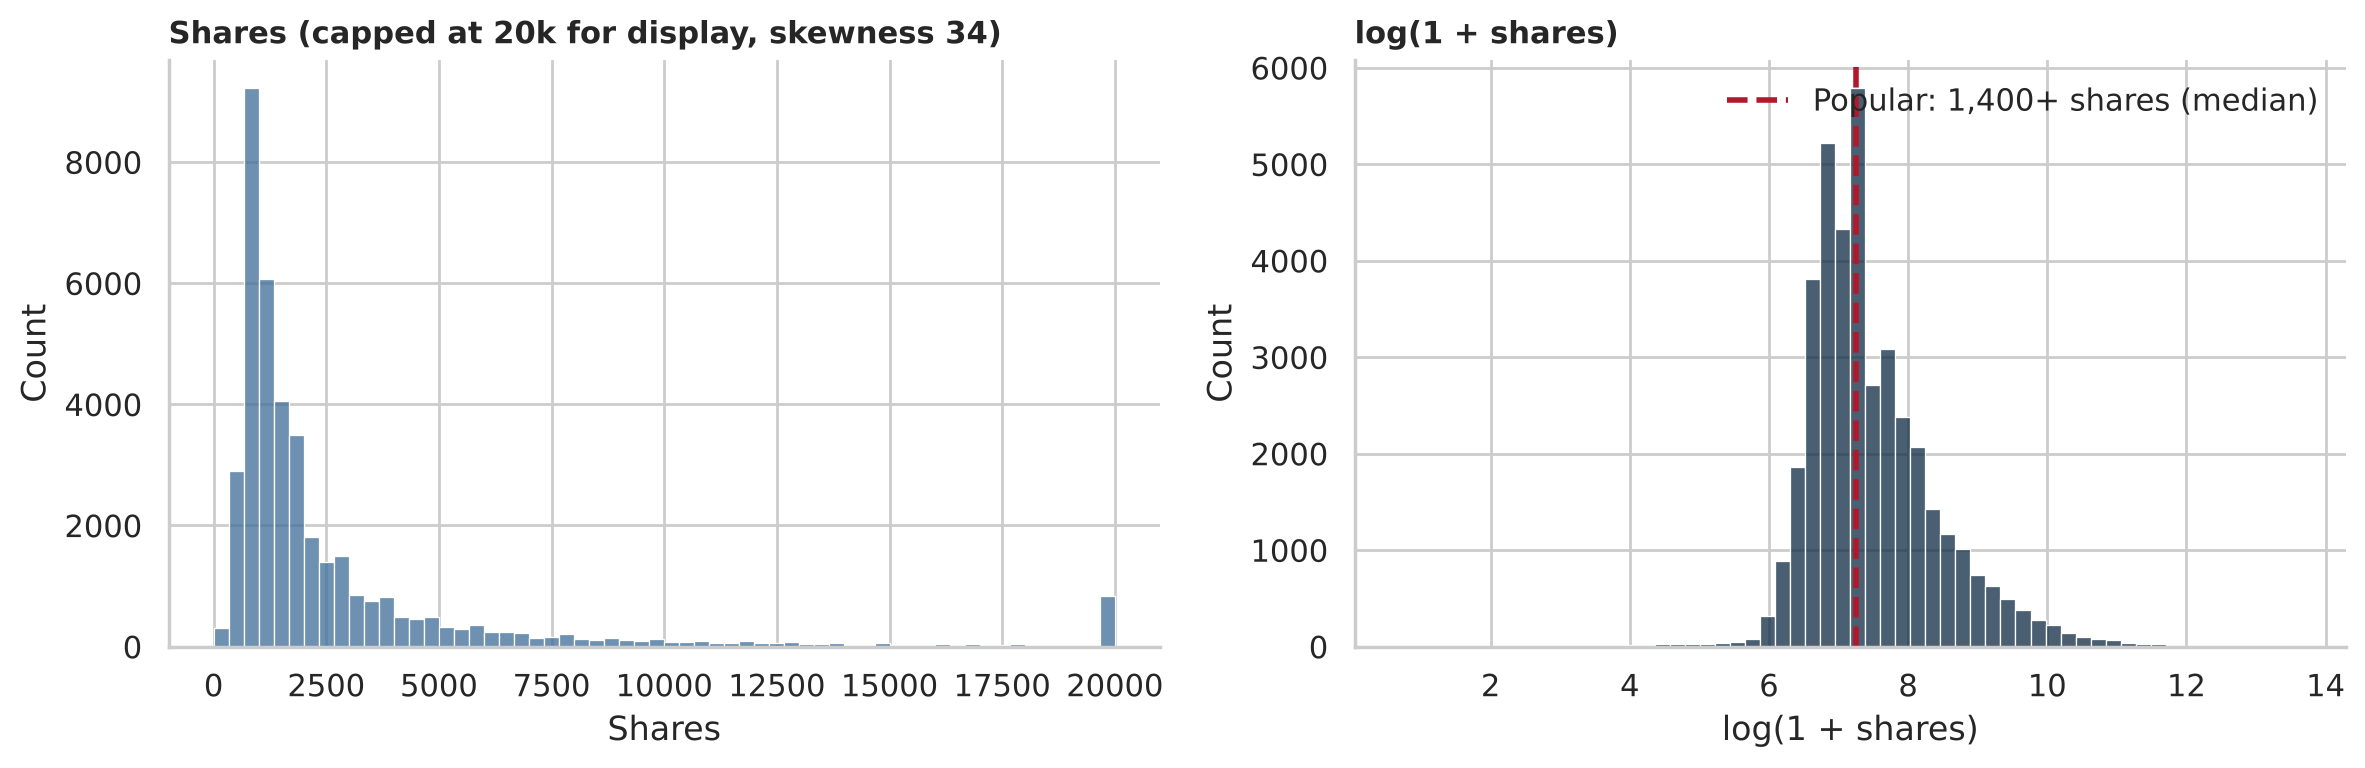

In [6]:
save(plot_shares_distribution(df), "shares_distribution.png")

Shares are extremely skewed: the median is 1,400 but the maximum is 843,300. This is why the main task is classifying popular articles, with predicting log(shares) as a secondary check.

## 4. What gets shared

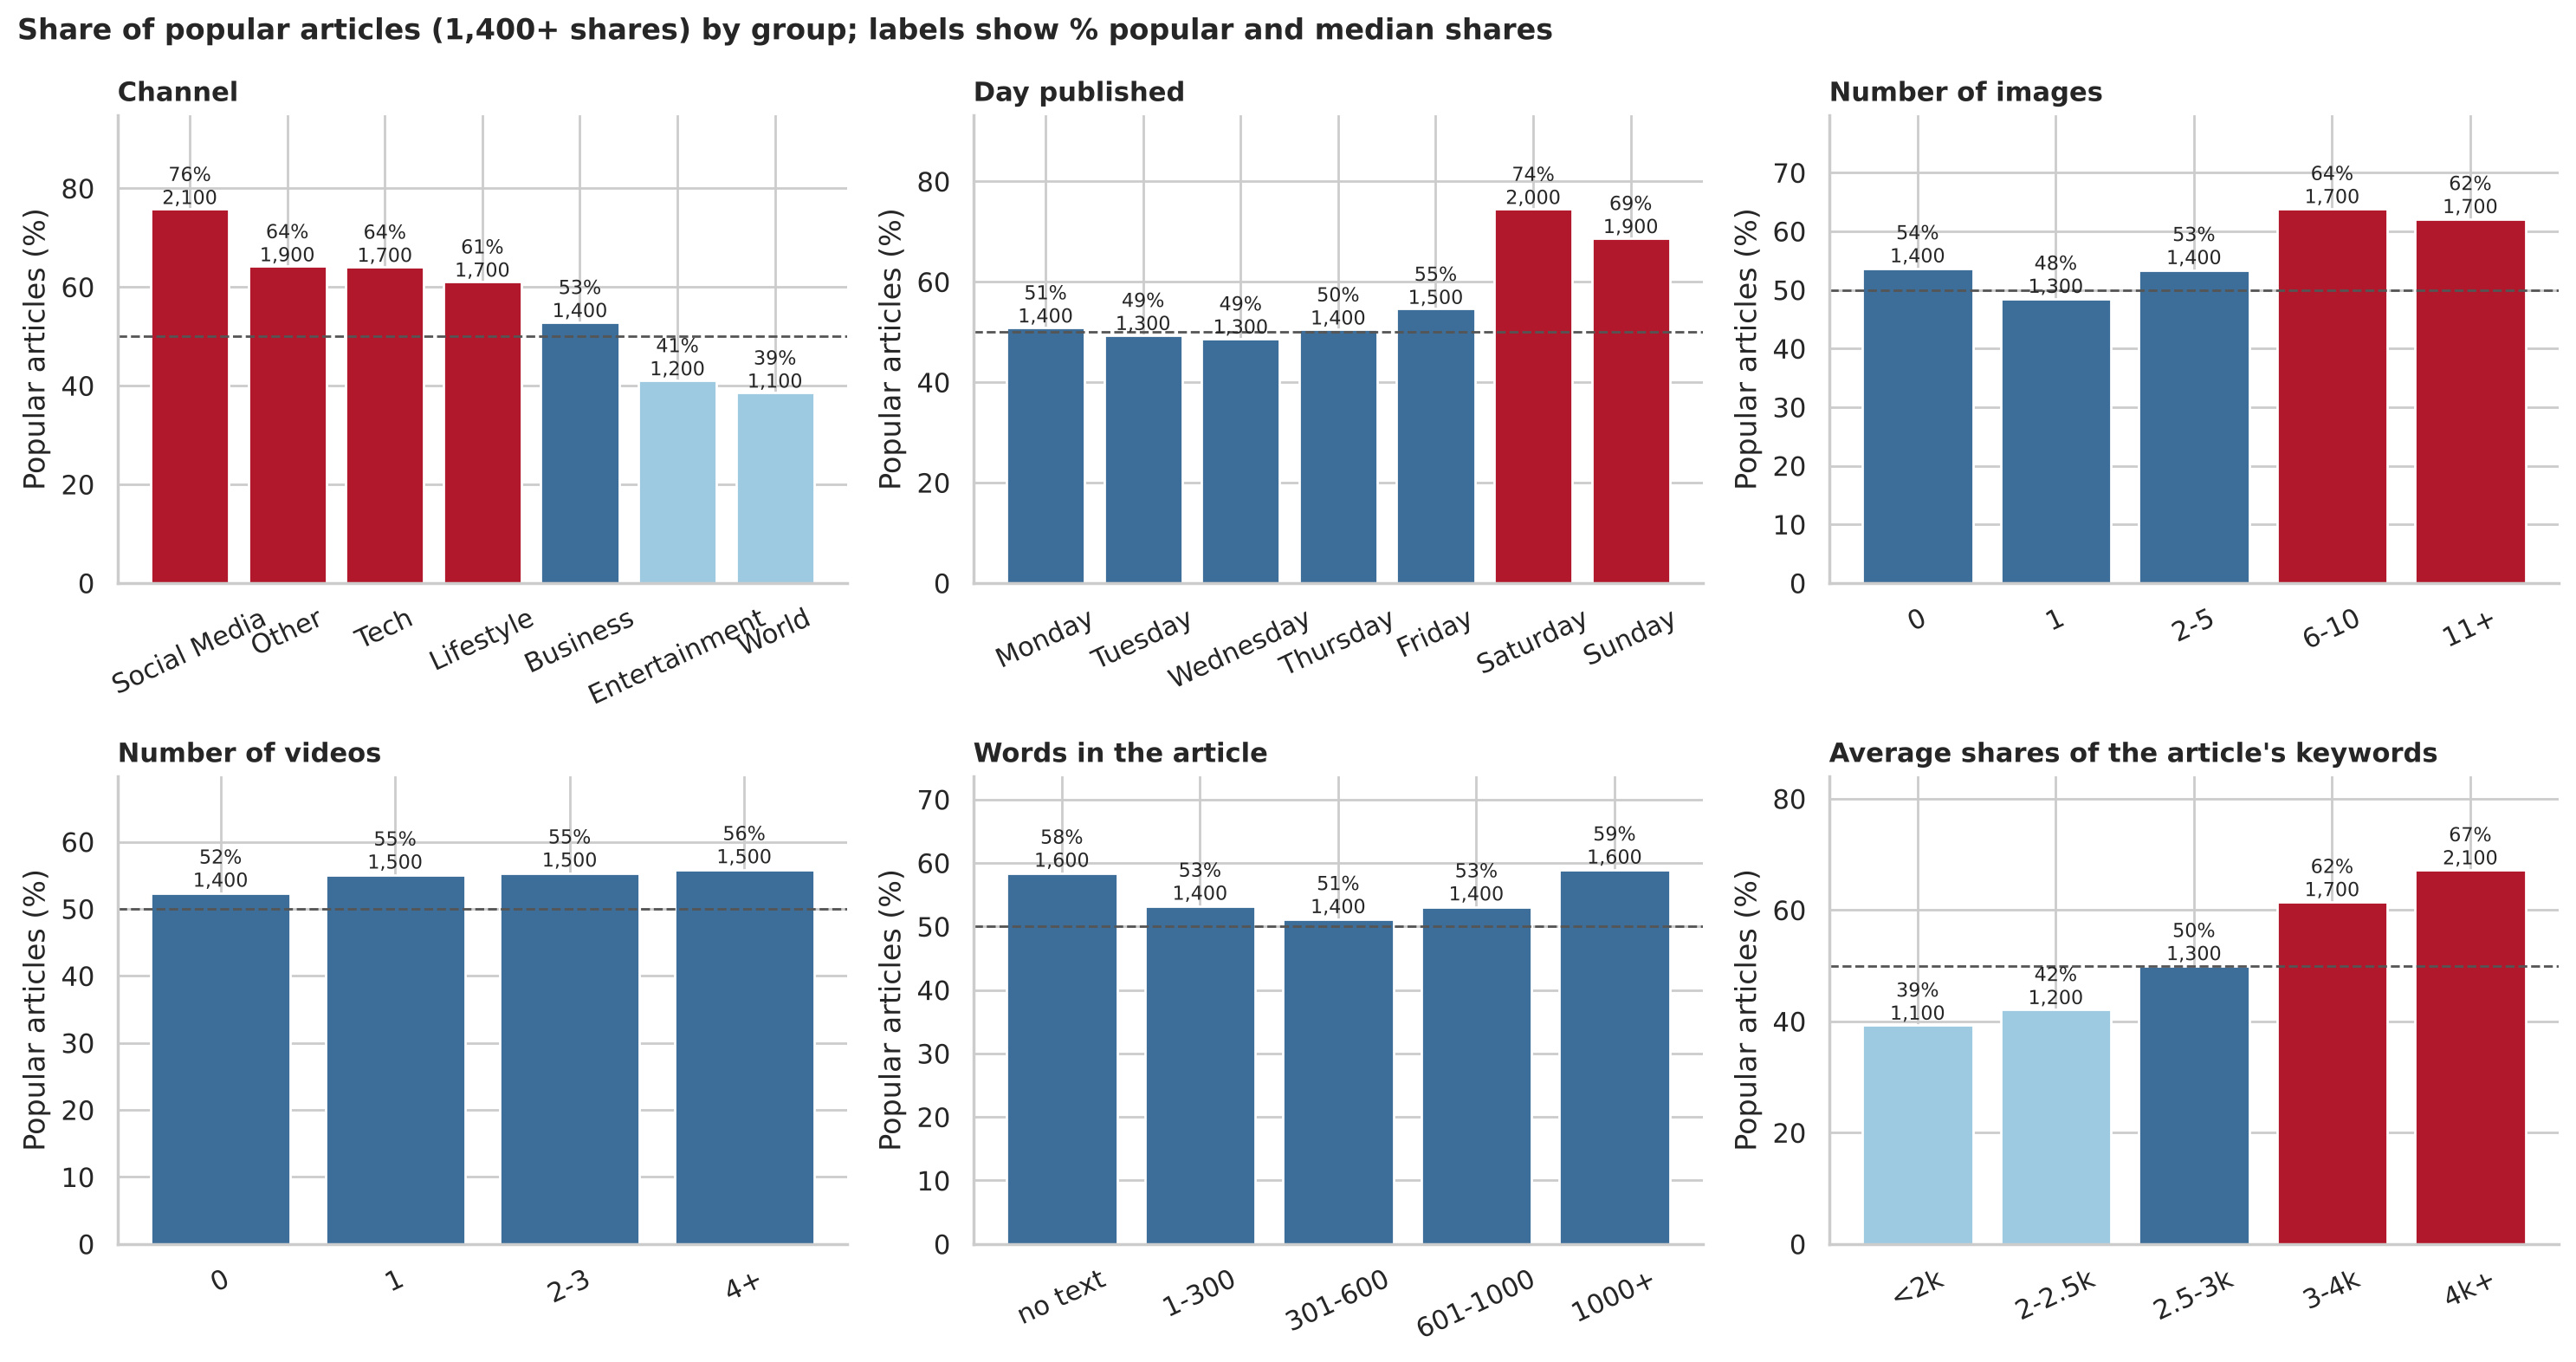

In [7]:
save(plot_popularity_overview(df), "popularity_by_group.png")

In [8]:
display(shares_by(df, "channel").sort_values("popular_%", ascending=False))
display(shares_by(df, "weekday").set_index("weekday").loc[WEEK_ORDER].reset_index())

,channel,articles,median_shares,popular_%
4,Social Media,2323,2100.0,75.8
3,Other,6134,1900.0,64.2
5,Tech,7346,1700.0,64.1
2,Lifestyle,2099,1700.0,61.1
0,Business,6258,1400.0,52.9
1,Entertainment,7056,1200.0,41.1
6,World,8427,1100.0,38.6


,weekday,articles,median_shares,popular_%
0,Monday,6661,1400.0,50.9
1,Tuesday,7389,1300.0,49.4
2,Wednesday,7435,1300.0,48.7
3,Thursday,7267,1400.0,50.5
4,Friday,5701,1500.0,54.6
5,Saturday,2453,2000.0,74.5
6,Sunday,2737,1900.0,68.7


In [9]:
w = weekend_test(df)
print(f"Median shares, weekend: {w['median_weekend']:,.0f} | weekday: {w['median_weekday']:,.0f}")
print(f"Mann-Whitney U test p-value: {w['p_value']:.1e}")

Median shares, weekend: 1,900 | weekday: 1,400
Mann-Whitney U test p-value: 1.7e-200


In [10]:
rank_correlations(df, feature_columns(df))

,feature,spearman
0,kw_avg_avg,0.256
1,kw_max_avg,0.223
2,self_reference_avg_sharess,0.192
3,self_reference_min_shares,0.182
4,self_reference_max_shares,0.169
5,data_channel_is_world,-0.168
6,LDA_02,-0.157
7,is_weekend,0.152
8,data_channel_is_entertainment,-0.115
9,global_subjectivity,0.114


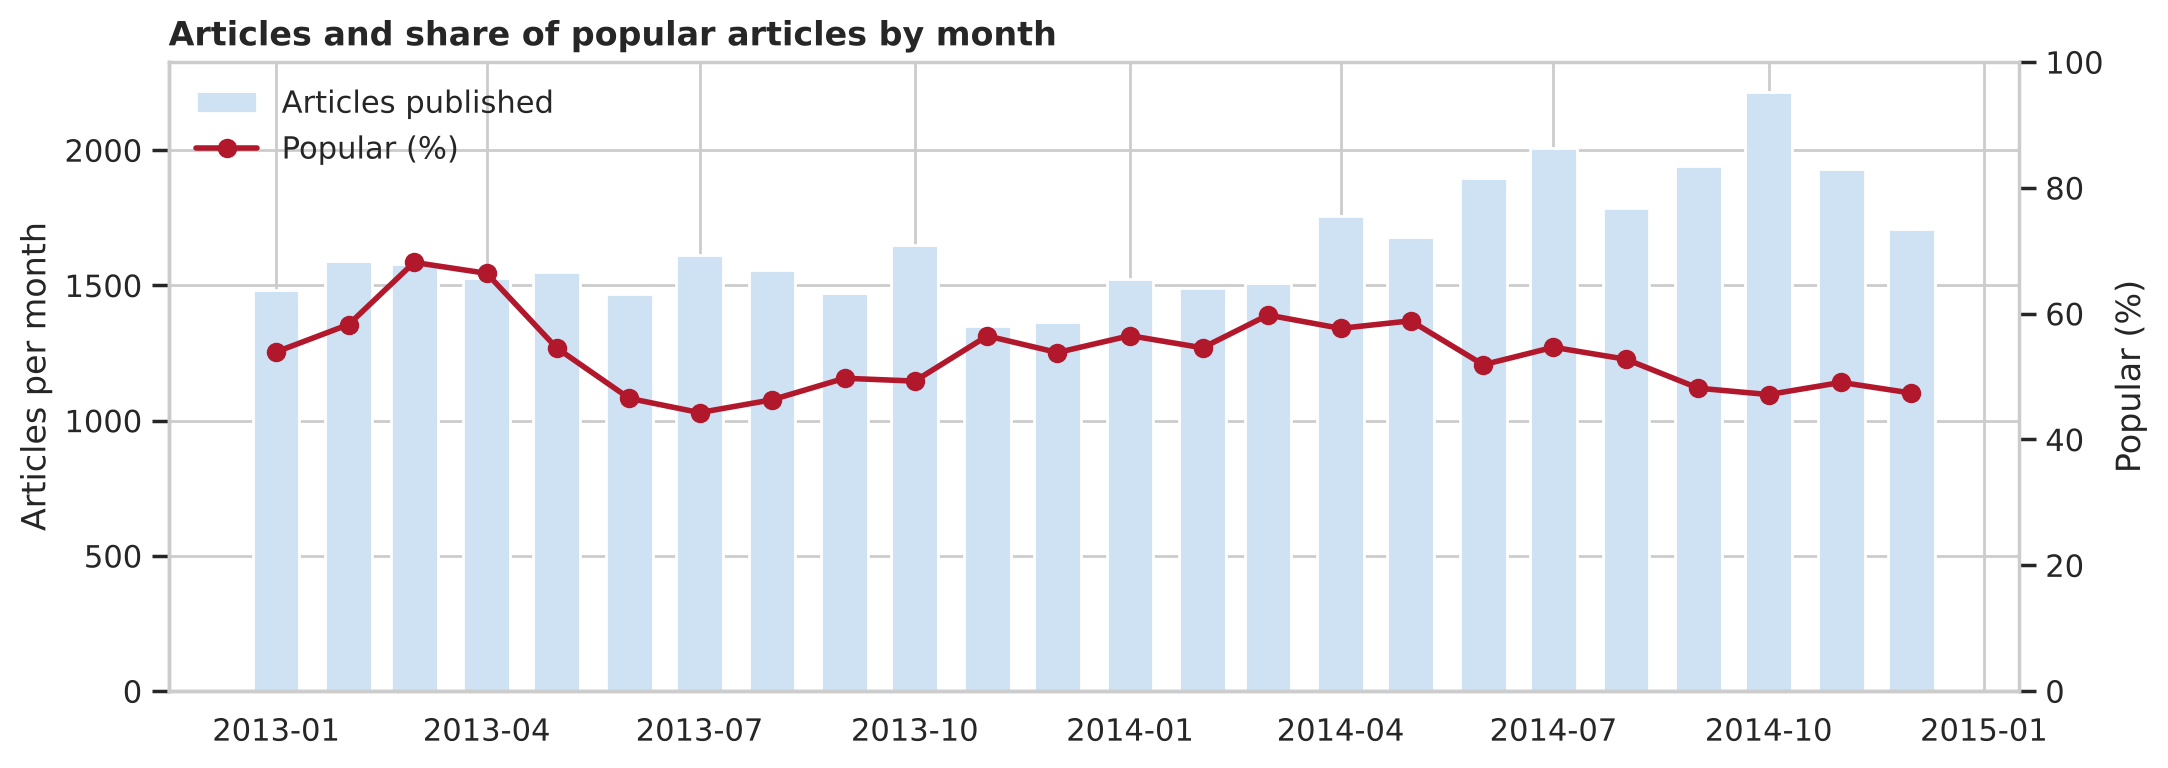

In [11]:
save(plot_monthly(df), "monthly.png")

The share of popular articles is lower in late 2014. Newer articles had less time to collect shares before the data was gathered, so the most recent test period is slightly harder than the training period.

## 5. Modeling approach

- **Inputs:** the 58 article features plus the no-text flag (channel, weekday, word counts, links, images, videos, keyword and self-reference share statistics, LDA topic weights, sentiment and subjectivity).
- **Split by time:** train on the oldest 80% of articles (January 2013 to August 2014) and test on the newest 20% (August to December 2014). This is how the model would be used: trained on the past, applied to new articles.
- **Main metric:** ROC-AUC, because the goal is to rank articles, not to hit an exact count.

In [12]:
train, test = time_split(df)
print(f"Train: {len(train):,} articles, {train['publish_date'].min().date()} to {train['publish_date'].max().date()}, {train['popular'].mean():.1%} popular")
print(f"Test:  {len(test):,} articles, {test['publish_date'].min().date()} to {test['publish_date'].max().date()}, {test['popular'].mean():.1%} popular")

Train: 31,714 articles, 2013-01-07 to 2014-08-28, 54.7% popular
Test:  7,929 articles, 2014-08-28 to 2014-12-27, 47.9% popular


## 6. Model comparison

In [13]:
comparison, probas = compare_classifiers(df)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

,model,ROC_AUC,accuracy,precision,recall,F1
0,Always predict the majority class,0.500,0.479,0.479,1.000,0.648
1,Logistic Regression,0.714,0.658,0.636,0.671,0.653
2,Random Forest,0.733,0.670,0.642,0.707,0.673
3,Gradient Boosting,0.736,0.669,0.643,0.698,0.669


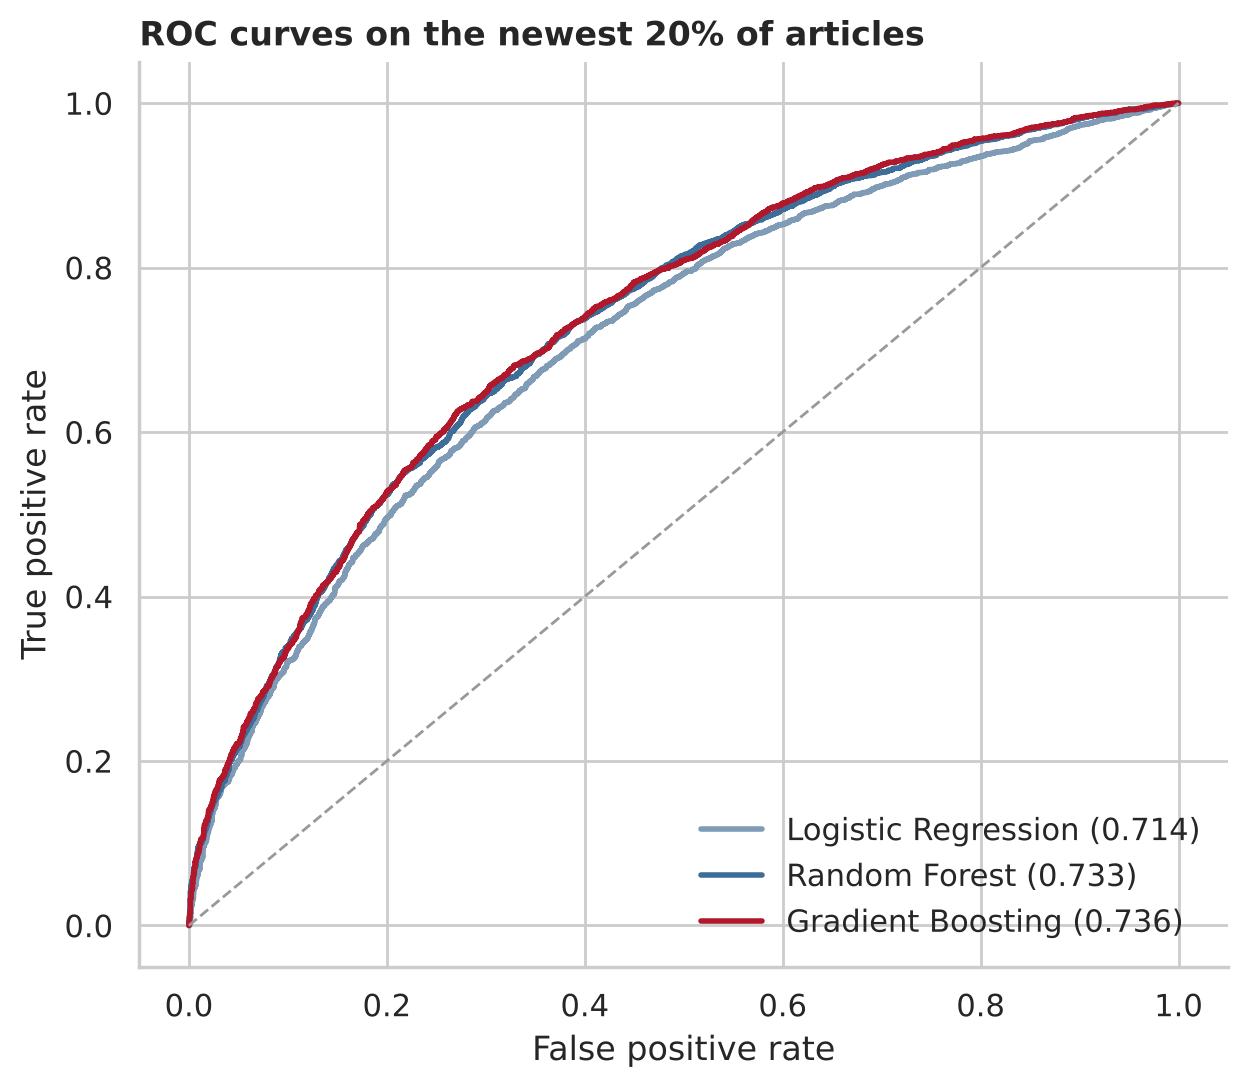

In [14]:
save(plot_roc(test["popular"].values, probas), "roc_curves.png")

In [15]:
validation_check(df)

,validation,ROC_AUC
0,Random 5-fold cross-validation,0.737
1,"Train on older 80%, test on newest 20%",0.736


Random cross-validation and the time split give the same ROC-AUC, so the model holds up on articles published after the training period.

In [16]:
lift = lift_table(test["popular"].values, probas["Gradient Boosting"])
lift.to_csv(RESULTS / "lift_table.csv", index=False)
lift

,group,articles,popular_rate
0,Top 20% by score,1586,76.4
1,20-40%,1586,61.8
2,40-60%,1585,46.9
3,60-80%,1586,35.4
4,Bottom 20%,1586,19.2


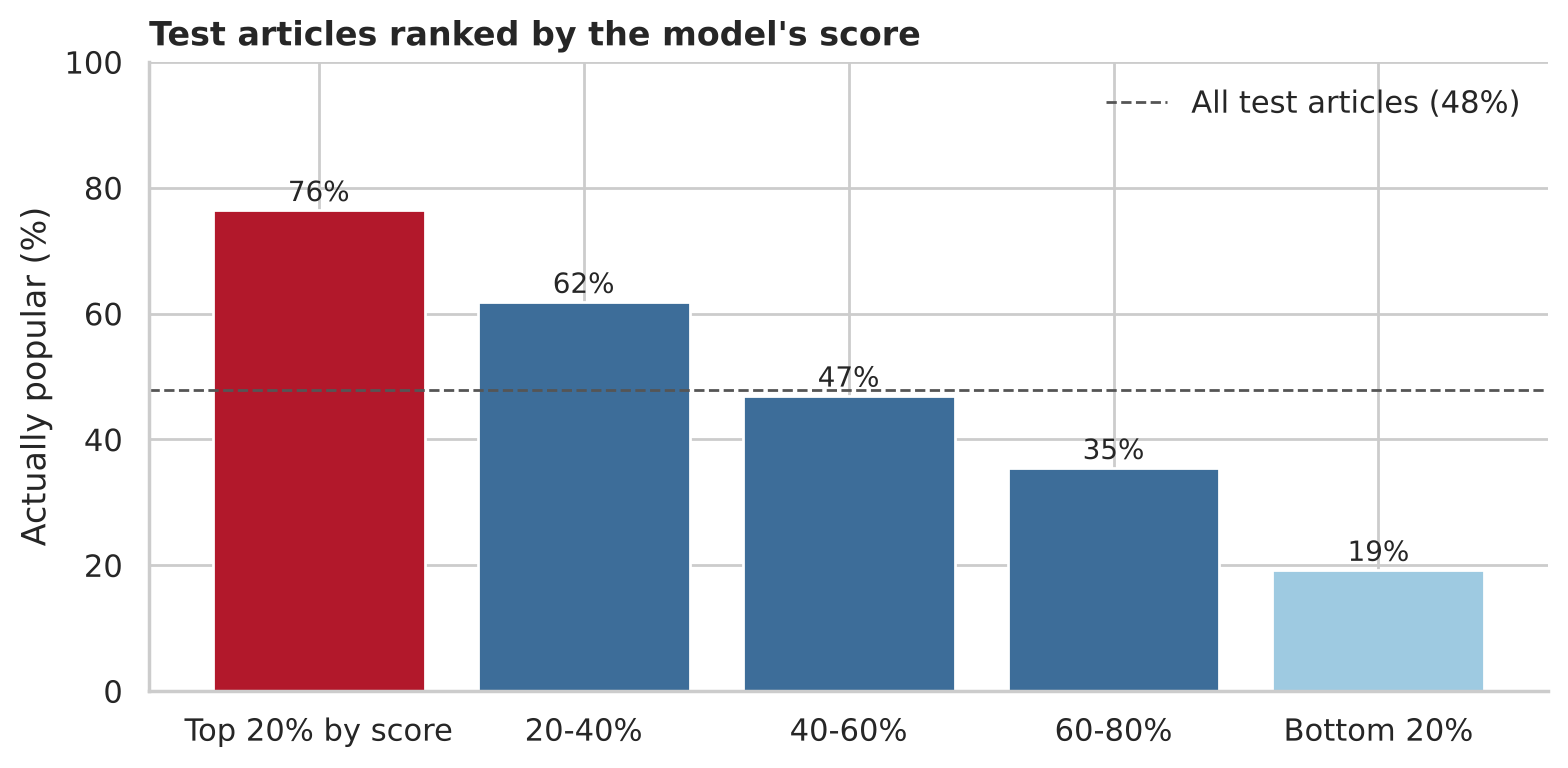

In [17]:
save(plot_lift(lift, test["popular"].mean()), "lift.png")

### Predicting the number of shares

In [18]:
regression_result(df)

,model,R2_log_shares,MAE_log_shares,within_2x_%
0,Predict the training median,-0.006,0.653,67.701
1,Gradient Boosting,0.151,0.609,68.558


Predicting the exact count is much harder (R2 0.15 on log shares). Many shares depend on things outside the article, such as whether a large account picks it up.

## 7. What the model relies on

In [19]:
importance = feature_importance(df)
importance.to_csv(RESULTS / "feature_importance.csv", index=False)
importance.head(15)

,feature,AUC_drop
0,kw_avg_avg,0.0294
1,self_reference_min_shares,0.0131
2,is_weekend,0.0128
3,data_channel_is_tech,0.0078
4,data_channel_is_entertainment,0.0077
5,num_hrefs,0.0062
6,self_reference_avg_sharess,0.0055
7,n_unique_tokens,0.0051
8,LDA_00,0.0050
9,kw_min_avg,0.0048


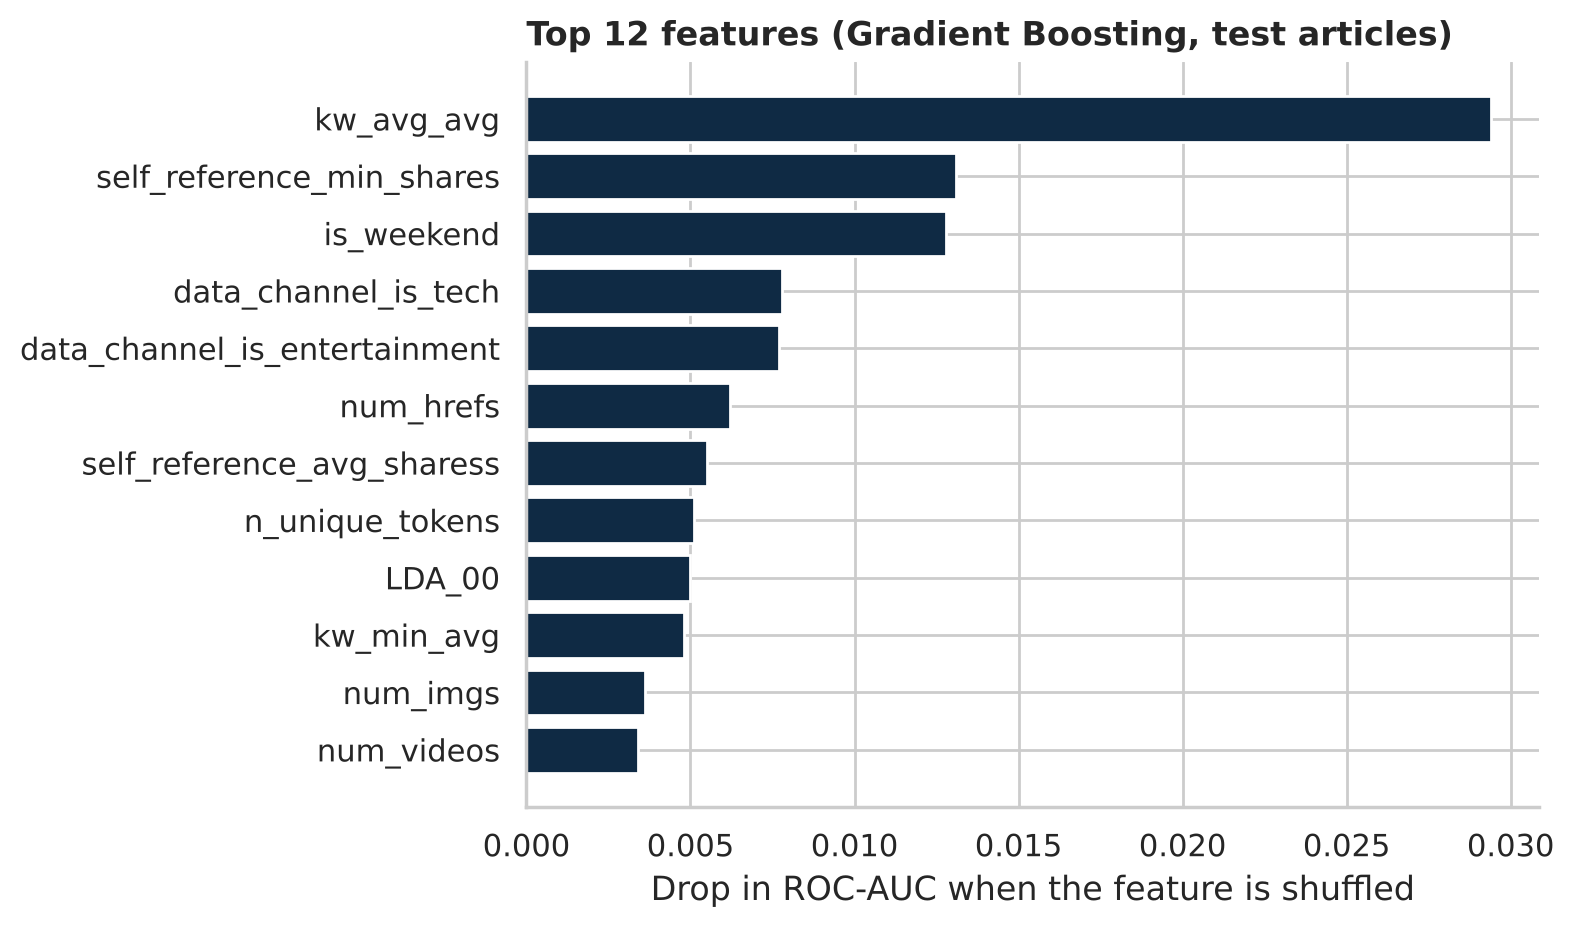

In [20]:
save(plot_feature_importance(importance), "feature_importance.png")

## 8. Findings

1. **Channel matters most for the basic rate.** 76% of Social Media channel articles reach 1,400+ shares, against 41% for Entertainment and 39% for World.
2. **Weekend articles are shared more.** 74% of Saturday articles and 69% of Sunday articles are popular, against about 49% midweek. Median shares are 1,900 at the weekend and 1,400 on weekdays (Mann-Whitney p < 0.001).
3. **Keywords with a strong track record predict popularity.** Articles whose keywords averaged over 4,000 past shares are popular 67% of the time, against 39% below 2,000. This is the model's most important feature.
4. **More images help a little** (62 to 64% popular with six or more images, against 48% with one). Video count and article length make little difference.
5. **The model ranks articles well.** Gradient Boosting reaches ROC-AUC 0.736 on the newest articles. Of the 20% it scored highest, 76% were popular, against 19% of the lowest 20%.

**Limitations:** one publisher and two years; share counts depend on events outside the article; and recent articles had less time to collect shares.